# Proyección Monte Carlo de la tabla — Zona A (2026)

Simula el resto de la Zona A miles de veces para estimar la probabilidad de
cada posición final, de descenso y de entrar al Torneo Reducido por posición
de zona.

**Modelo:** Dixon-Coles (1997). Ataque y defensa de cada equipo, ventaja de
localía y dependencia entre los goles del local y del visitante, todo
estimado junto por máxima verosimilitud sobre los partidos de las dos zonas
(así cada resultado queda corregido por la calidad del rival), con el xG
entrando como observación auxiliar. Los ratings son **estáticos**: se ajustan
una vez y no se actualizan dentro de la simulación. Paper en `docs/papers/`,
implementación en `src/analysis/dixon_coles.py`.

**Hiperparámetros (`XI`, `W_XG`):** salen del backtesting de la sección 4, no
de criterio propio. Los defaults viven en `config.py` (`DC_XI`, `DC_W_XG`).

**Alcance (Fase 1, ver `PLAN_montecarlo_tabla.md`):** solo Zona A. No calcula
ascenso directo ni el Reducido completo, que dependen de la Zona B (Fase 2,
no implementada), aunque los ratings del modelo ya cubren a los 36 equipos.

In [1]:
import os, sys
%load_ext autoreload
%autoreload 2
if os.path.basename(os.getcwd()) in ('primera_nacional', 'liga_profesional'):
    os.chdir('..')
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd(); sys.path.insert(0, PROJECT_ROOT)
import pandas as pd
import config
from src.analysis import liga
from src.analysis import simulation as sim
from src.scraping import fixture_scraper as FX
from src.reports import liga as rliga
from IPython.display import Image, display
def show(p):
    if p and os.path.exists(p): display(Image(filename=p))

## 1. Configuración

**¿Cuántas simulaciones (`N_SIMS`) conviene correr?** Es solo precisión vs.
tiempo — el modelo en sí no cambia. Con ~130 partidos restantes de Zona A,
medido en esta máquina:

| N_SIMS | Tiempo aprox. | Cuándo usarlo |
|---|---|---|
| 5.000 | <1s | prueba rápida / iterar el modelo |
| 20.000 | ~3s | **default recomendado** — ya estabiliza bien las probabilidades |
| 50.000 | ~7s | previo a mandar el informe, para las colas (equipos límite tipo 8°/9° o 16°/17°) |
| 100.000+ | ~15s+ | no aporta mucho más que 50.000 en un torneo de 18 equipos; no hace falta |

In [2]:
SEASON = '2026'
N_SIMS = 100000           # ver tabla de arriba
SEED = None              # fijar un entero para resultados reproducibles
HIGHLIGHT = 'Chaco For Ever'
MODELO = 'dc'             # 'dc' = Dixon-Coles (default); 'legacy' = modelo viejo de promedios
XI = None                 # decaimiento temporal por día; None = config.DC_XI (0.0)
W_XG = None               # peso del xG en el rating; None = config.DC_W_XG (0.8)
CORTE = 18                # fecha de corte para el backtesting de la sección 4
ACTUALIZAR_FIXTURE = False  # True = re-scrapea el calendario completo (~5-10 min, 36 fechas)

## 2. Calendario (fixture)

El fixture completo (36 equipos, jugados y por jugar) se scrapea una sola vez
y se cachea en `data/temporadas/{SEASON}/fixture.csv`. Solo hace falta
re-scrapear cuando se jugó una fecha nueva o se reprogramó algún partido —
activá `ACTUALIZAR_FIXTURE` arriba. El scraping recorre las 36 fechas del
torneo (Zona A + Zona B) con pausas de `config.MIN_DELAY`-`config.MAX_DELAY`
segundos entre requests para no gatillar el bloqueo de SofaScore.

In [3]:
if ACTUALIZAR_FIXTURE:
    FX.fetch_fixture(season=SEASON)
else:
    fx = FX.load_fixture(SEASON)
    if fx is None:
        print('No hay fixture.csv cacheado — corré con ACTUALIZAR_FIXTURE=True al menos una vez.')
    else:
        print(f'Fixture cacheado: {len(fx)} partidos totales.')

rem = FX.remaining_fixture_zona_a(SEASON)
print(f'Partidos restantes de Zona A (deduplicados): {len(rem)}')

Fixture cacheado: 791 partidos totales.
Partidos restantes de Zona A (deduplicados): 18


## 3. Simulación y gráficos

Antes de simular: una cota MATEMÁTICA (no probabilística) de "piso" (si un
equipo no suma más puntos) y "techo" (si gana todo lo que le queda), para
saber si a esta altura ya es matemáticamente imposible que alguien descienda
o se salve — independiente de cómo juegue nadie. Con muchos partidos por
jugar esto casi nunca aplica todavía; el 0%/100% que después muestra la
simulación es una certeza ESTADÍSTICA (el escenario es tan improbable que
no aparece en decenas de miles de corridas), no una certeza matemática —
son dos cosas distintas y vale la pena tener ambas.

In [4]:
bounds = sim.points_bounds(SEASON)
n_salvados = (bounds['estado_matematico'] == 'Matemáticamente salvado').sum()
print(f'Equipos ya matemáticamente salvados del descenso: {n_salvados} de {len(bounds)}')
bounds_show = bounds.rename(columns={
    'position': 'Pos. actual', 'team_name': 'Equipo', 'points': 'Pts.',
    'matches_played': 'PJ', 'restantes': 'Restantes', 'piso': 'Piso', 'techo': 'Techo',
    'rivales_que_podrian_superarlo': 'Rivales que podrían superarlo (peor caso)',
    'estado_matematico': 'Estado',
})[['Pos. actual', 'Equipo', 'Pts.', 'PJ', 'Restantes', 'Piso', 'Techo',
    'Rivales que podrían superarlo (peor caso)', 'Estado']]
display(bounds_show.set_index('Pos. actual'))

Equipos ya matemáticamente salvados del descenso: 11 de 18


,Equipo,Pts.,PJ,Restantes,Piso,Techo,Rivales que podrían superarlo (peor caso),Estado
Pos. actual,,,,,,,,
1,Club Ferro Carril Oeste,65,34,2,65,71,1,Matemáticamente salvado
2,Godoy Cruz,60,34,2,60,66,4,Matemáticamente salvado
3,Deportivo Morón,58,34,2,58,64,4,Matemáticamente salvado
4,Deportivo Madryn,54,34,2,54,60,7,Matemáticamente salvado
5,Club Atletico Colón,54,34,2,54,60,7,Matemáticamente salvado
6,Ciudad de Bolivar,51,34,2,51,57,7,Matemáticamente salvado
7,Almirante Brown,48,34,2,48,54,7,Matemáticamente salvado
8,Estudiantes de Buenos Aires,48,34,2,48,54,7,Matemáticamente salvado
9,Los Andes,41,34,2,41,47,15,Matemáticamente salvado


In [5]:
res = liga.generate_projection_graphics(SEASON, n_sims=N_SIMS, seed=SEED, highlight=HIGHLIGHT,
                                        model=MODELO, xi=XI, w_xg=W_XG)

Modelo: Dixon-Coles (xi=0.0, w_xg=0.8, rho=-0.081, gamma=1.512)
Chaco For Ever: posición media 10.8° (mediana 10°) | descenso 0% | reducido por posición 0% | 1° de zona 0%
  ✔ posicion_probabilidad.png
  ✔ distribucion_puntos.png
  ✔ proyeccion_zona.png


### 3.1 Tabla proyectada (fácil de leer)

Ordenada por "Pos. actual" (la tabla de HOY, `standings.csv`), no por la
posición proyectada — así cada equipo aparece donde está parado ahora, y al
lado se ve hacia dónde lo mueve la proyección ("Pos. proyectada" / "Δ vs.
hoy") junto con el % de simulaciones en que terminó puntero / en zona de
Reducido por posición / en descenso.

In [6]:
from src.scraping.standings_scraper import load_standings

_st_now = load_standings(SEASON)[['team_name', 'position', 'points', 'matches_played']].rename(
    columns={'position': 'Pos. actual', 'points': 'Pts. actuales', 'matches_played': 'PJ'})

proj_sorted = res['proj'].sort_values('posicion_media').reset_index(drop=True)
proj_sorted['Pos. proyectada'] = range(1, len(proj_sorted) + 1)

tabla = proj_sorted[['team_name', 'Pos. proyectada', 'posicion_media', 'posicion_mediana',
                     'prob_puntero_zona_a', 'prob_reducido_por_posicion', 'prob_descenso']].copy()
tabla = tabla.merge(_st_now, on='team_name', how='left')
tabla['Δ vs. hoy'] = tabla['Pos. proyectada'] - tabla['Pos. actual']
tabla = tabla.rename(columns={
    'team_name': 'Equipo',
    'posicion_media': 'Posición media',
    'posicion_mediana': 'Posición mediana',
    'prob_puntero_zona_a': '% 1° de zona',
    'prob_reducido_por_posicion': '% Reducido (pos.)',
    'prob_descenso': '% Descenso',
})
tabla['Posición media'] = tabla['Posición media'].round(1)
for c in ['% 1° de zona', '% Reducido (pos.)', '% Descenso']:
    tabla[c] = (tabla[c] * 100).round(0).astype(int).astype(str) + '%'
tabla = tabla.sort_values('Pos. actual')
tabla = tabla[['Pos. actual', 'Pos. proyectada', 'Δ vs. hoy', 'Equipo', 'Pts. actuales', 'PJ',
                'Posición media', 'Posición mediana', '% 1° de zona', '% Reducido (pos.)', '% Descenso']]
display(tabla.set_index('Pos. actual'))

,Pos. proyectada,Δ vs. hoy,Equipo,Pts. actuales,PJ,Posición media,Posición mediana,% 1° de zona,% Reducido (pos.),% Descenso
Pos. actual,,,,,,,,,,
1,1,0,Club Ferro Carril Oeste,65,34,1.0,1.0,97%,3%,0%
2,2,0,Godoy Cruz,60,34,2.2,2.0,3%,97%,0%
3,3,0,Deportivo Morón,58,34,2.9,3.0,0%,100%,0%
4,4,0,Deportivo Madryn,54,34,4.3,4.0,0%,100%,0%
5,5,0,Club Atletico Colón,54,34,4.6,5.0,0%,100%,0%
6,6,0,Ciudad de Bolivar,51,34,6.5,6.0,0%,100%,0%
7,8,1,Almirante Brown,48,34,7.4,8.0,0%,100%,0%
8,7,-1,Estudiantes de Buenos Aires,48,34,7.1,7.0,0%,100%,0%
9,9,0,Los Andes,41,34,9.8,9.0,0%,0%,0%


### 3.1b Validación: Dixon-Coles vs. el modelo viejo

Corre los dos modelos con el mismo `seed` para ver cuánto mueve a cada equipo
el cambio. El modelo viejo (promedios normalizados, Poisson independiente,
recencia con vida media de 6 partidos) reacciona mucho más a las rachas; el
backtesting de la sección 4 muestra que esa reacción no mejora el pronóstico.
Las diferencias grandes aparecen justo en los equipos que vienen de una racha
marcada.

In [7]:
_seed_cmp = SEED if SEED is not None else 42
_sims_old = sim.simulate_season(SEASON, n_sims=30000, seed=_seed_cmp, model='legacy', half_life=6)
_sims_dc  = sim.simulate_season(SEASON, n_sims=30000, seed=_seed_cmp, model='dc', xi=XI, w_xg=W_XG)
_proj_old = sim.promotion_relegation_probabilities(_sims_old).set_index('team_name')
_proj_dc  = sim.promotion_relegation_probabilities(_sims_dc).set_index('team_name')

cmp = pd.DataFrame({
    'Pos. media (viejo)': _proj_old['posicion_media'],
    'Pos. media (DC)': _proj_dc['posicion_media'],
    '% Descenso (viejo)': (_proj_old['prob_descenso'] * 100).round(1),
    '% Descenso (DC)': (_proj_dc['prob_descenso'] * 100).round(1),
})
cmp['Delta posicion'] = (cmp['Pos. media (DC)'] - cmp['Pos. media (viejo)']).round(2)
cmp['Delta % descenso'] = (cmp['% Descenso (DC)'] - cmp['% Descenso (viejo)']).round(1)
cmp = cmp.merge(_st_now.set_index('team_name')[['Pos. actual']], left_index=True, right_index=True)
cmp.index.name = 'Equipo'
display(cmp.sort_values('Pos. actual').round(2))

,Pos. media (viejo),Pos. media (DC),% Descenso (viejo),% Descenso (DC),Delta posicion,Delta % descenso,Pos. actual
Equipo,,,,,,,
Club Ferro Carril Oeste,1.06,1.03,0.0,0.0,-0.03,0.0,1
Godoy Cruz,2.12,2.22,0.0,0.0,0.10,0.0,2
Deportivo Morón,3.03,2.89,0.0,0.0,-0.14,0.0,3
Deportivo Madryn,4.22,4.35,0.0,0.0,0.13,0.0,4
Club Atletico Colón,4.63,4.56,0.0,0.0,-0.07,0.0,5
Ciudad de Bolivar,6.47,6.45,0.0,0.0,-0.02,0.0,6
Almirante Brown,7.50,7.39,0.0,0.0,-0.11,0.0,7
Estudiantes de Buenos Aires,6.96,7.11,0.0,0.0,0.15,0.0,8
Los Andes,10.20,9.83,0.0,0.0,-0.37,0.0,9


### 3.2 Posiciones finales más probables por equipo

En vez de la matriz completa (equipo x las 18 posiciones), esto muestra
directo las 3 posiciones más probables de cada uno con su %. Sirve para ver
rápido el "piso y techo" realista de cada equipo, no solo el promedio.
Ordenado por posición ACTUAL, igual que 3.1.

In [8]:
_pos_cols = [c for c in res['pos_probs'].columns if c.startswith('pos_')]

def _top_posiciones(row, n=3):
    vals = sorted(((int(c.split('_')[1]), row[c]) for c in _pos_cols), key=lambda x: -x[1])
    return ' / '.join(f"{p}° ({v*100:.0f}%)" for p, v in vals[:n] if v > 0)

detalle = res['pos_probs'][['team_name']].copy()
detalle['Posiciones más probables'] = res['pos_probs'].apply(_top_posiciones, axis=1)
detalle = (detalle.merge(_st_now[['team_name', 'Pos. actual']], on='team_name')
           .sort_values('Pos. actual')
           .rename(columns={'team_name': 'Equipo'})
           .set_index('Pos. actual')
           [['Equipo', 'Posiciones más probables']])
display(detalle)

,Equipo,Posiciones más probables
Pos. actual,,
1,Club Ferro Carril Oeste,1° (97%) / 2° (3%)
2,Godoy Cruz,2° (73%) / 3° (23%) / 1° (3%)
3,Deportivo Morón,3° (65%) / 2° (24%) / 4° (9%)
4,Deportivo Madryn,4° (53%) / 5° (39%) / 3° (6%)
5,Club Atletico Colón,5° (55%) / 4° (36%) / 3° (5%)
6,Ciudad de Bolivar,6° (55%) / 7° (31%) / 8° (9%)
7,Almirante Brown,8° (53%) / 7° (32%) / 6° (14%)
8,Estudiantes de Buenos Aires,8° (37%) / 7° (36%) / 6° (26%)
9,Los Andes,9° (55%) / 10° (21%) / 11° (12%)


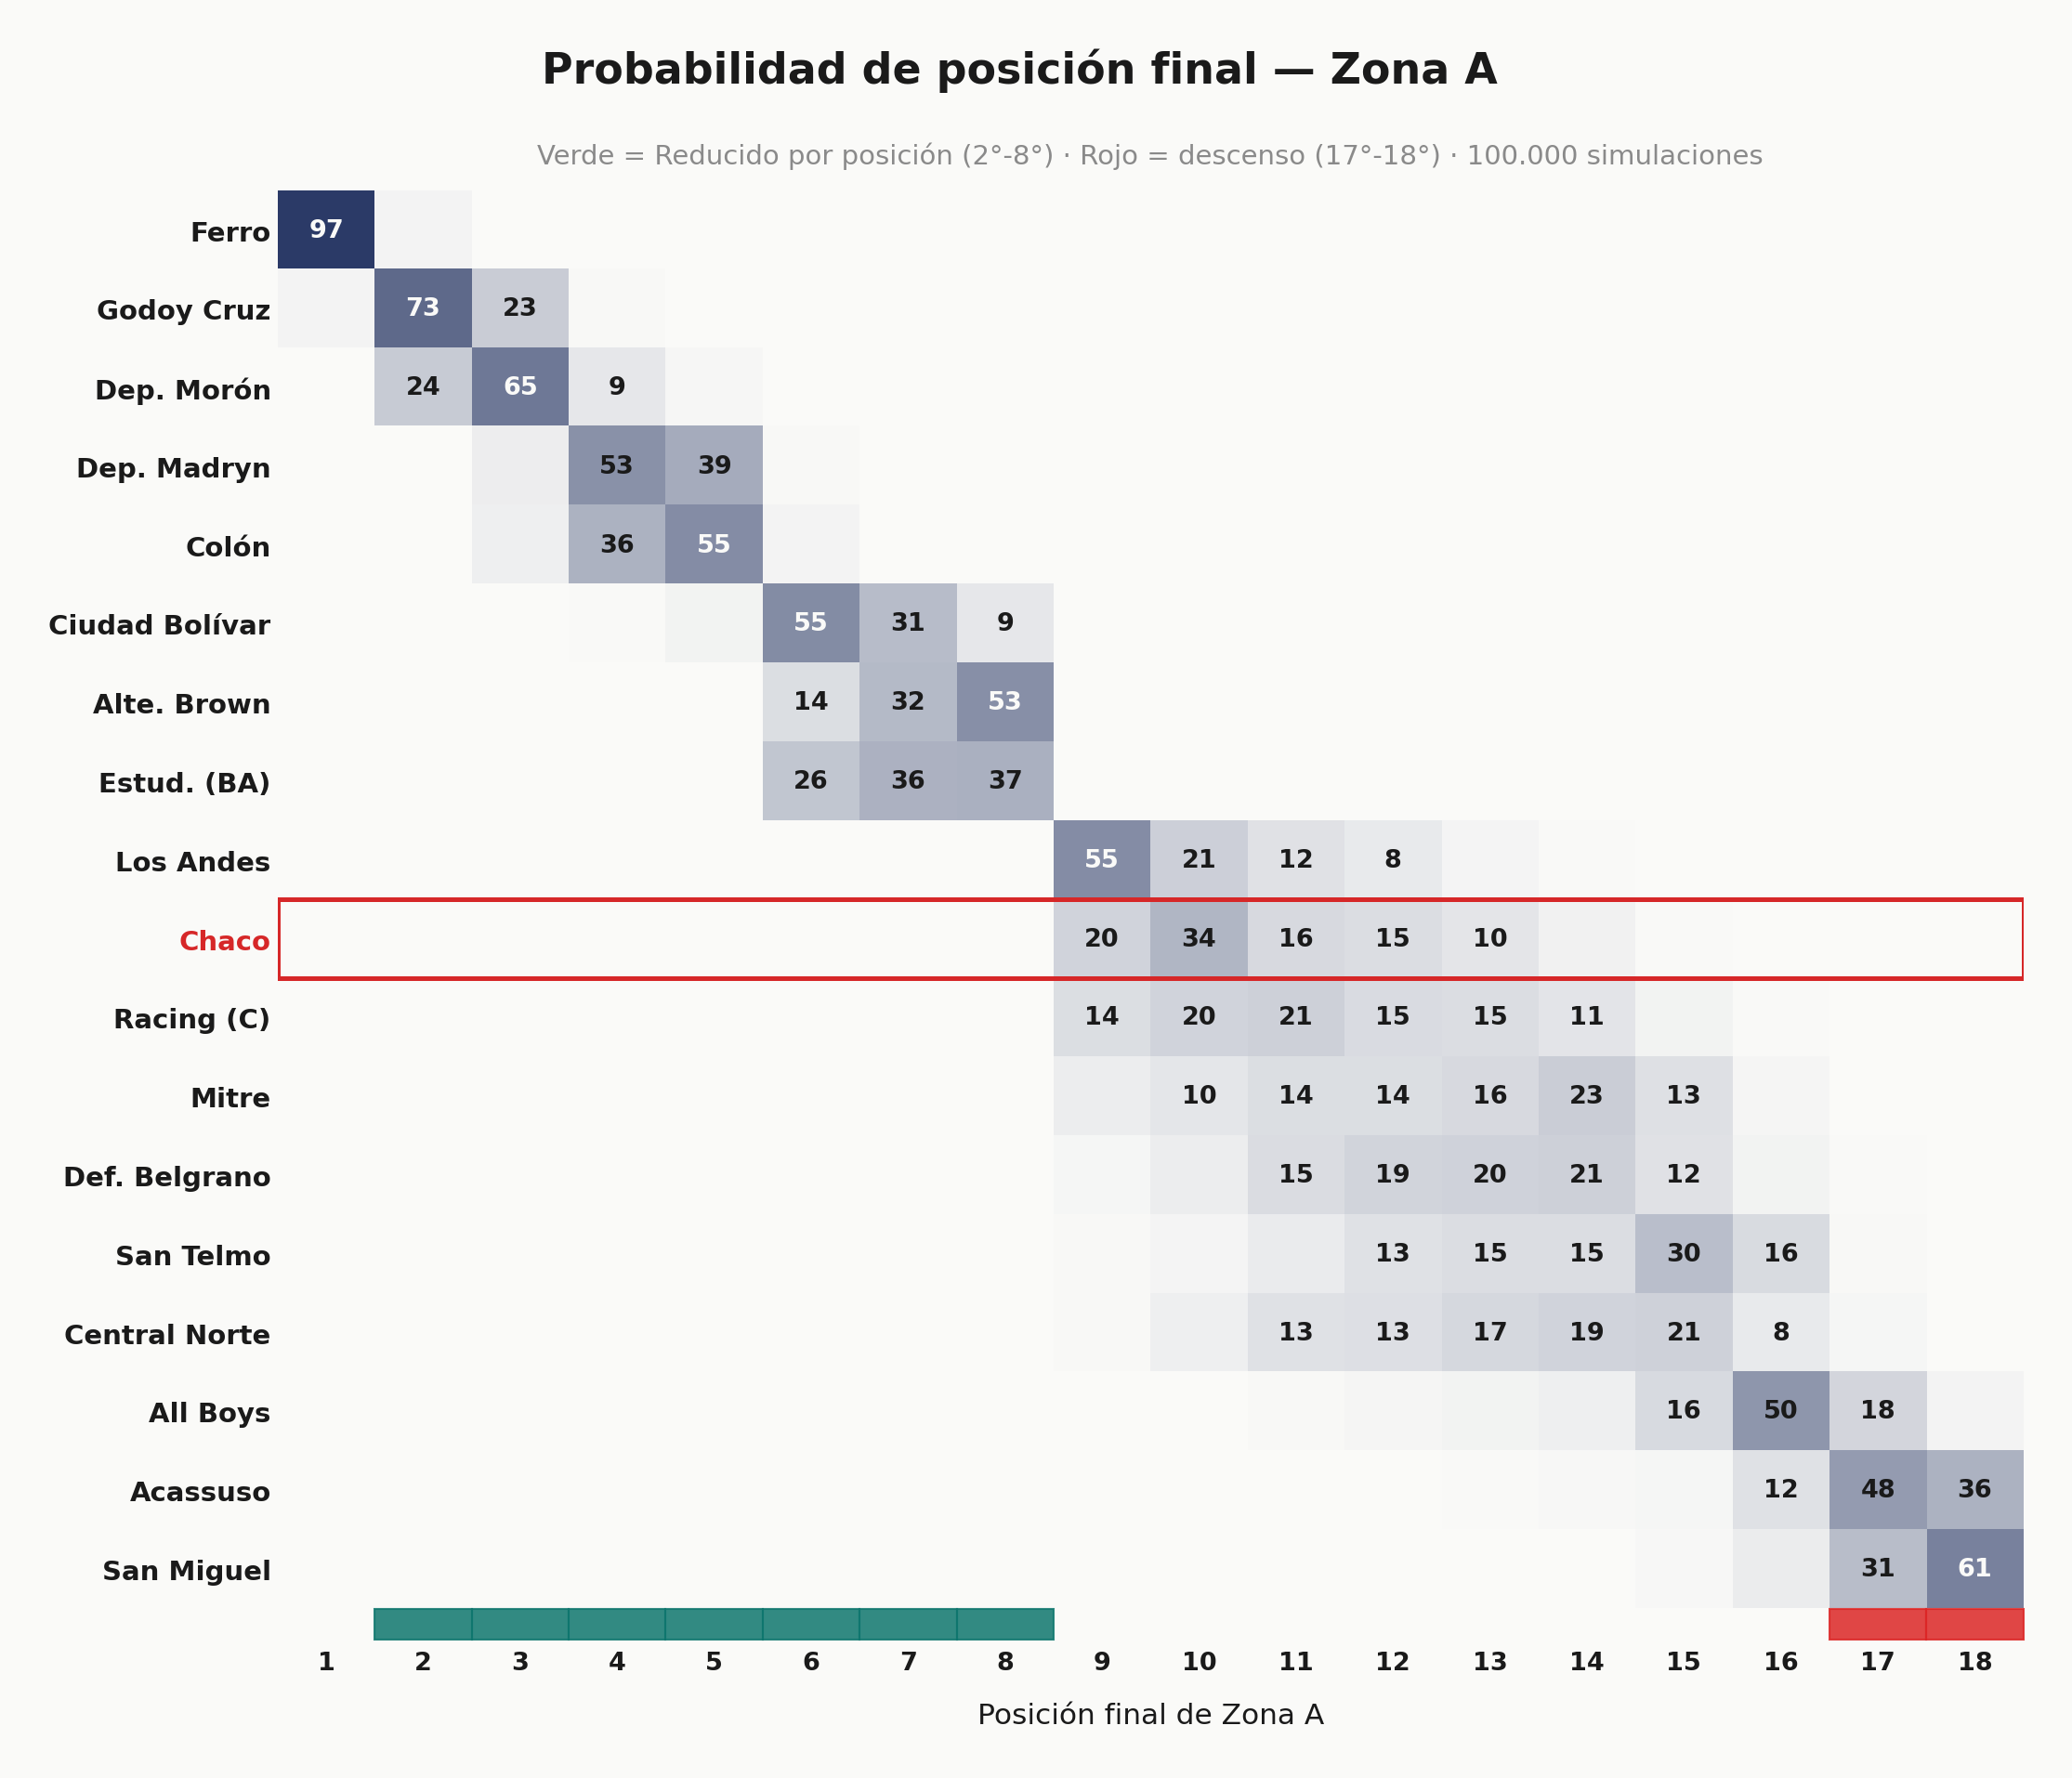

In [9]:
show(res['graphics']['posicion_probabilidad.png'])

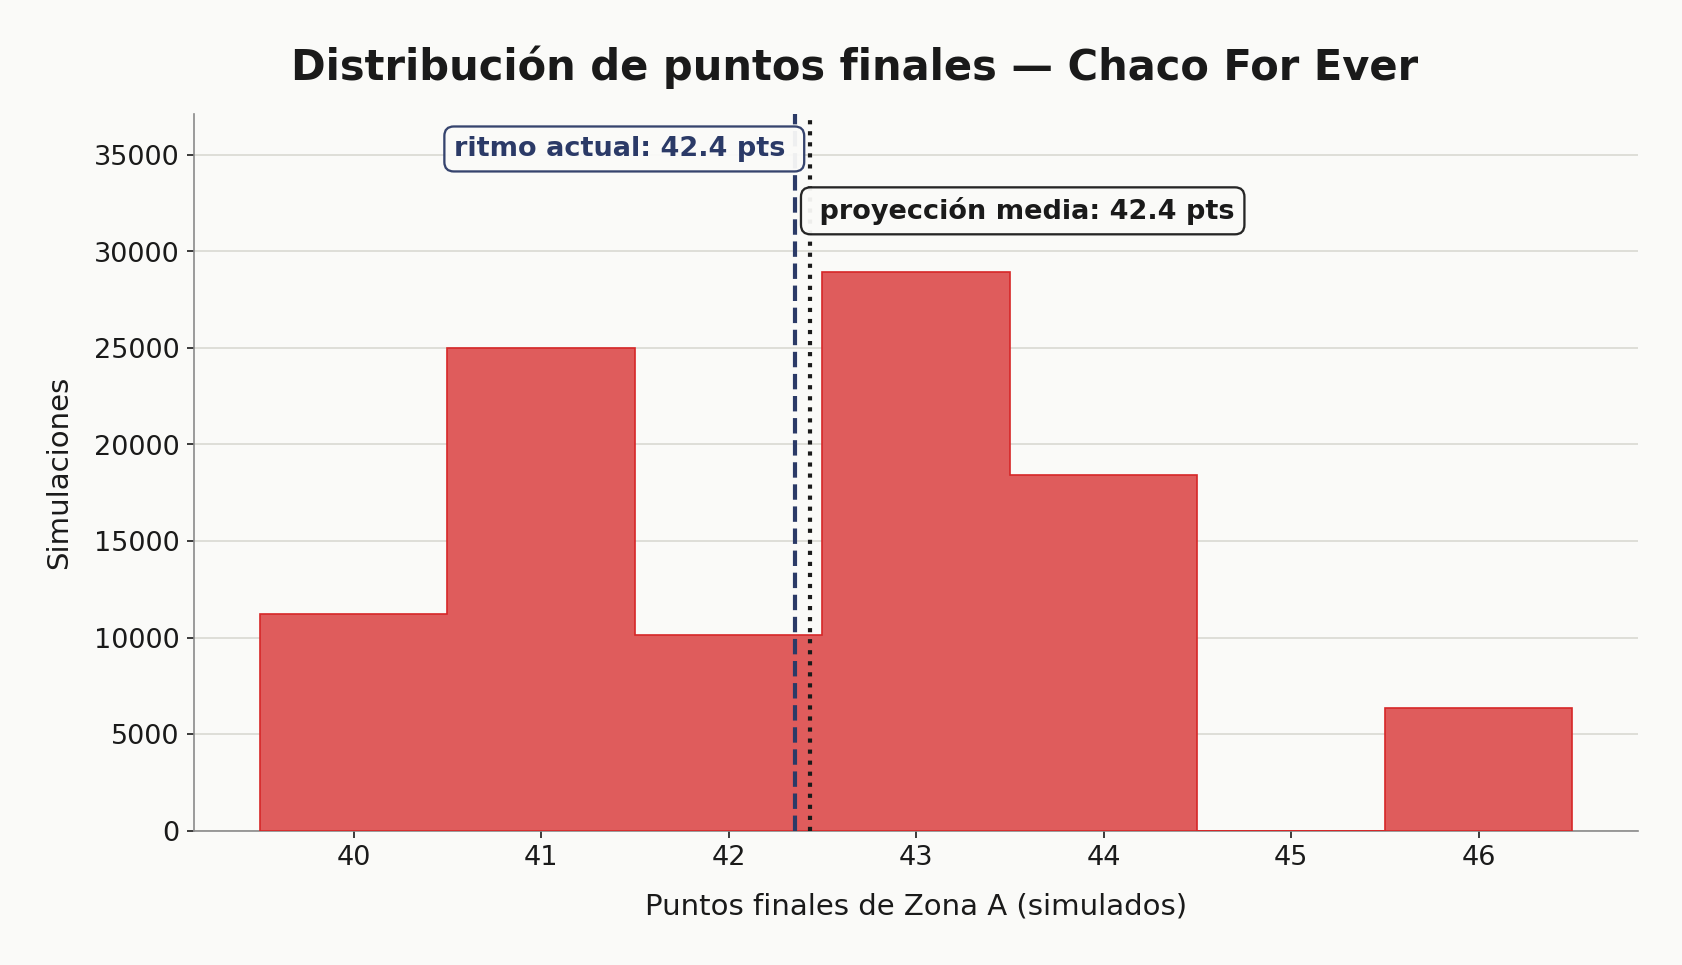

In [10]:
show(res['graphics']['distribucion_puntos.png'])

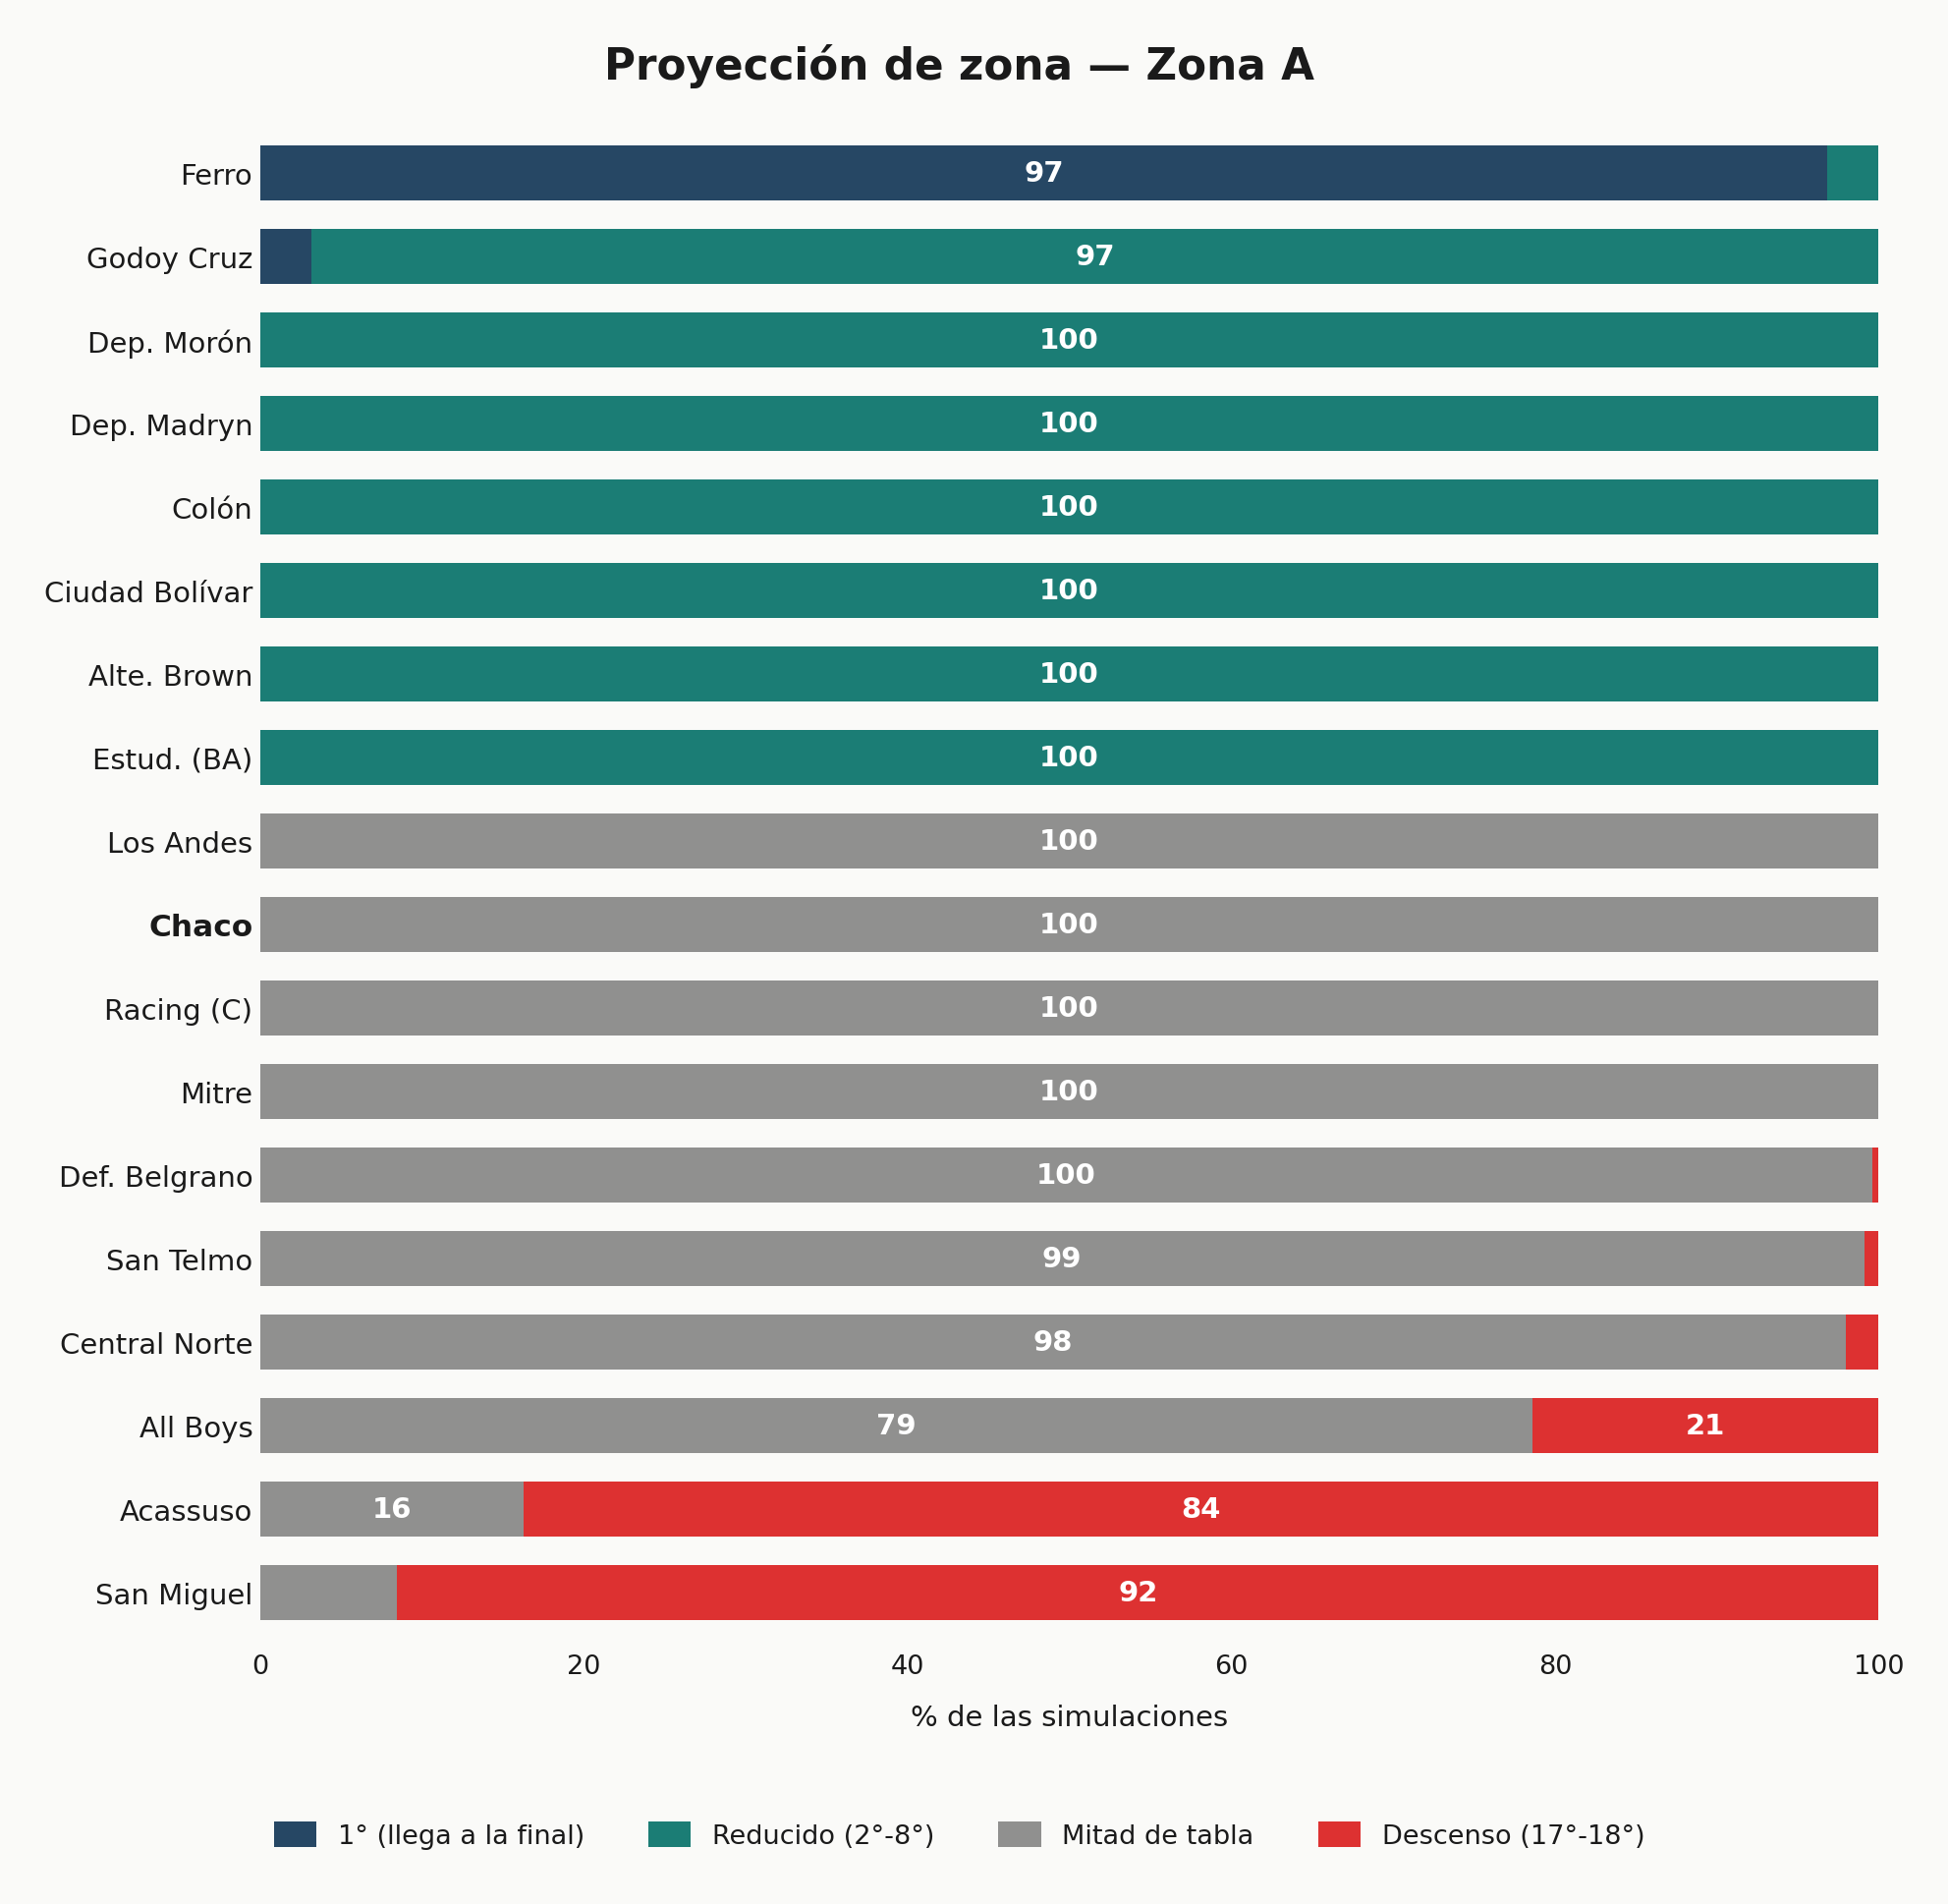

In [11]:
show(res['graphics']['proyeccion_zona.png'])

## 4. Backtesting

Cortar el campeonato en una fecha pasada, ajustar el modelo **solo** con lo
jugado hasta ahí y medir contra lo que después pasó de verdad. Es lo que fija
los hiperparámetros y lo que dice si la simulación miente o no.

Métricas: **log-loss** (la de la ecuación 4.7 del paper de Dixon-Coles: qué
probabilidad le puso el modelo al resultado que efectivamente ocurrió, menos
es mejor) y **RPS**, el estándar del pronóstico de fútbol, que castiga menos
equivocarse "cerca" (dar favorito al que empata) que "lejos".

In [12]:
from src.analysis import dixon_coles as DC
from src.analysis import backtest as BT

_m = DC.build_match_table(SEASON)
_fit = DC.fit(_m, xi=XI, w_xg=W_XG, verbose=True)
_names = dict(zip(_m.home_team_id, _m.home_team))
_names.update(dict(zip(_m.away_team_id, _m.away_team)))
print(f"partidos usados: {len(_m)} | con xG: {int(_m.home_xg.notna().sum())}")
display(DC.strengths_table(_fit, _names).round(3))

DC fit: 611 partidos, 36 equipos, xi=0.0, w_xg=0.8 | gamma=1.512 rho=-0.081 level=0.891 | ok=True
partidos usados: 611 | con xG: 602


,team_id,team_name,ataque,defensa
0,6074,Godoy Cruz,1.442,0.755
1,5292,Gimnasia Y Esgrima De Jujuy,1.279,1.126
2,36841,Club Ferro Carril Oeste,1.246,0.632
3,3207,Club Atletico Colón,1.212,0.700
4,93109,Deportivo Morón,1.203,0.759
5,222120,Deportivo Madryn,1.191,0.876
6,265787,Agropecuario Argentino,1.182,1.073
7,213042,Deportivo Maipú,1.153,0.874
8,4936,Quilmes Atlético Club,1.150,0.933
9,93107,Estudiantes de Buenos Aires,1.112,0.817


### 4.1 Elección de los hiperparámetros

Grilla de xi (decaimiento temporal, por día) y w_xg (peso del xG en el
rating) con origen móvil: se repite el corte en varias fechas y se promedia,
para no quedarse con lo que anduvo bien en un corte por casualidad. **Ojo:**
las ventanas de prueba de cortes sucesivos se pisan, así que los promedios no
son independientes entre sí; sirven para comparar celdas de la grilla, no
como error estándar.

In [13]:
_tune = BT.tune(SEASON, verbose=False)
print('mejores combinaciones (log-loss, menos es mejor):')
display(_tune.head(8).round(4))
print('log-loss - filas: peso del xG, columnas: decaimiento por dia')
display(_tune.pivot_table(index='w_xg', columns='xi', values='logloss').round(4))

mejores combinaciones (log-loss, menos es mejor):


,xi,w_xg,half_life_dias,logloss,rps,brier,acierto,S,n
0,0.0015,0.6,462.0981,1.0388,0.2082,0.6238,0.4689,-1611.2351,1547
1,0.0000,0.6,inf,1.0388,0.2082,0.6238,0.4706,-1611.1849,1547
2,0.0030,0.6,231.0491,1.0389,0.2082,0.6238,0.4700,-1611.4374,1547
3,0.0050,0.6,138.6294,1.0391,0.2083,0.6239,0.4661,-1611.9314,1547
4,0.0000,0.8,inf,1.0393,0.2081,0.6235,0.4726,-1611.8835,1547
5,0.0015,0.8,462.0981,1.0393,0.2081,0.6235,0.4775,-1611.9681,1547
6,0.0030,0.8,231.0491,1.0394,0.2082,0.6235,0.4756,-1612.1743,1547
7,0.0050,0.8,138.6294,1.0397,0.2083,0.6236,0.4777,-1612.6303,1547


log-loss - filas: peso del xG, columnas: decaimiento por dia


xi,0.0000,0.0015,0.0030,0.0050,0.0080,0.0120,0.0200
w_xg,,,,,,,
0.00,1.0647,1.0649,1.0655,1.0666,1.0691,1.0740,1.0884
0.15,1.0532,1.0533,1.0536,1.0543,1.0559,1.0592,1.0690
0.30,1.0456,1.0456,1.0457,1.0462,1.0473,1.0496,1.0565
0.45,1.0409,1.0409,1.0410,1.0413,1.0421,1.0438,1.0489
0.60,1.0388,1.0388,1.0389,1.0391,1.0397,1.0411,1.0451
0.80,1.0393,1.0393,1.0394,1.0397,1.0403,1.0415,1.0451
1.00,1.0430,1.0431,1.0433,1.0437,1.0444,1.0459,1.0499


### 4.2 Corte en la fecha 18: Dixon-Coles contra el modelo viejo

Todo lo jugado después del corte, predicho con los ratings congelados en esa
fecha. La tabla de calibración de abajo se lee así: de los partidos donde el
modelo dio entre 40% y 50% a un resultado, ¿en qué proporción ocurrió? Si la
columna `frecuencia_real` sigue de cerca a `prob_media`, las probabilidades
son creíbles como probabilidades, no solo como ranking.

In [14]:
_ev = BT.evaluate(SEASON, cutoff_round=CORTE)
display(BT.calibration(_ev['pred_dc']).round(3))

Corte: fecha 18 (2026-06-14) | entrena con 295 partidos, predice 316
  Dixon-Coles (xi=0.0, w_xg=0.8, rho=-0.184, gamma=1.438)
    logloss 1.0380 | RPS 0.2080 | acierto 46.5% | goles 1.85 vs 2.06 reales | empates 35.8% vs 28.8%
  Modelo viejo (half_life=6 partidos, w_xg=0.5, Poisson independiente)
    logloss 1.0481 | RPS 0.2133 | acierto 46.2% | goles 2.44 vs 2.06 reales | empates 25.9% vs 28.8%


,rango,casos,prob_media,frecuencia_real
0,0%-10%,16,0.081,0.188
1,10%-20%,106,0.156,0.179
2,20%-30%,211,0.251,0.242
3,30%-40%,393,0.354,0.326
4,40%-50%,150,0.435,0.460
5,50%-60%,55,0.546,0.618
6,60%-70%,15,0.636,0.667
7,70%-100%,2,0.723,1.000


### 4.3 Qué aporta cada pieza

Misma métrica y mismos cortes, apagando una cosa por vez.

In [15]:
display(BT.ablation(SEASON).round(4))

,variante,logloss,rps,acierto
0,sin tau (Poisson indep),1.0313,0.2077,0.4738
1,DC completo,1.0393,0.2081,0.4726
2,sin decaimiento (xi=0),1.0393,0.2081,0.4726
3,solo xG (w_xg=1),1.0430,0.2089,0.4803
4,modelo viejo,1.0443,0.2116,0.4755
5,sin xG (w_xg=0),1.0647,0.2150,0.4634


### 4.4 La proyección entera, no los partidos sueltos

Se simula desde el corte con los ratings congelados y se compara los puntos
que cada equipo sacó **de verdad** contra su distribución simulada.

- `percentil` cerca de 0 = el equipo rindió mucho peor de lo proyectado;
  cerca de 1 = mucho mejor. Si el modelo está bien calibrado, los percentiles
  de los 36 equipos quedan repartidos entre 0 y 1.
- `cobertura del 80%` = en qué proporción de equipos los puntos reales
  cayeron dentro del intervalo 10%-90% de la simulación. Tiene que dar cerca
  de 80%: bastante menos significa que la simulación es demasiado confiada.

In [16]:
_pb = BT.projection_backtest(SEASON, cutoff_round=CORTE, n_sims=10000, seed=42)
display(_pb['tabla'].round(2))

Proyección desde la fecha 18 (2026-06-14), 316 partidos simulados 10000 veces
  MAE 4.91 pts | sesgo +0.61 | cobertura del 80%: 75% (27 de 36 equipos)


,team_id,team_name,pj_ventana,pts_reales,pts_simulados,p10,p90,percentil,error,dentro_80
0,224646,Güemes,18,7.0,17.43,12.0,24.0,0.01,-10.43,False
1,264945,San Miguel,18,12.0,22.25,16.0,29.0,0.02,-10.25,False
2,112497,Los Andes,18,15.0,24.08,18.0,31.0,0.03,-9.08,False
3,3200,Nueva Chicago,18,15.0,22.15,16.0,29.0,0.07,-7.15,False
4,52215,Defensores de Belgrano,17,18.0,24.58,18.0,31.0,0.09,-6.58,True
5,4936,Quilmes Atlético Club,17,18.0,24.52,18.0,31.0,0.09,-6.52,True
6,43741,Patronato,18,18.0,24.28,18.0,31.0,0.10,-6.28,True
7,93109,Deportivo Morón,17,24.0,27.49,21.0,34.0,0.24,-3.49,True
8,53799,Atlanta,17,25.0,28.39,22.0,35.0,0.25,-3.39,True
9,3207,Club Atletico Colón,17,25.0,28.39,22.0,35.0,0.25,-3.39,True


## 5. Sección de informe (LaTeX)

In [17]:
seccion_tex = rliga.build_projection_section_tex(
    res['sims'], res['proj'], team_name=HIGHLIGHT,
    graphics=set(res['graphics'].keys()),
)

out_path = os.path.join(res['plots_dir'], 'seccion_proyeccion.tex')
with open(out_path, 'w', encoding='utf-8') as f:
    f.write(seccion_tex)
print('Sección guardada en:', out_path)
print()
print(seccion_tex)

Sección guardada en: C:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\outputs\temporadas\2026\global_grupo_a\liga\proyeccion\seccion_proyeccion.tex

\section*{7. Proyección de la Tabla - Zona A}
Simulación Monte Carlo (100.000 temporadas simuladas, 18 partidos restantes de Zona A) sobre un modelo Dixon-Coles de ataque/defensa ajustado por máxima verosimilitud sobre los resultados de las dos zonas, corrigiendo cada partido por la calidad del rival y midiendo el rendimiento sobre todo por xG (80\%) más que por el gol convertido, que es lo que mejor predice fuera de muestra. \textbf{Alcance:} esto cubre solo la Zona A (18 equipos) - no incluye el ascenso directo (final vs. Zona B) ni el ganador del Torneo Reducido, que dependen de datos de la Zona B que hoy no están cargados (ver \texttt{PLAN\_montecarlo\_tabla.md}, Fase 2).

\databox{Proyección de Chaco For Ever}{Hoy está \textbf{10$^\circ$} con 40 pts en 34 PJ. Posición final esperada: \textbf{10.8$^\circ$} (mediana 10$^\circ$

## Notas

- Volvé a correr la sección 3 cada vez que se juegue una fecha nueva (y la
  sección 2 con `ACTUALIZAR_FIXTURE=True` si hubo partidos reprogramados, o
  si quedó alguno "en juego" al momento del último scrapeo).
- `N_SIMS` más alto = más precisión en las colas de la distribución, a costa
  de más segundos. 20.000 alcanza para leer bien las probabilidades de
  descenso/Reducido de la fecha actual.
- La sección 4 (backtesting) no hace falta correrla cada fecha: es para
  revisar el modelo o rever los hiperparámetros cada tanto, con más partidos
  acumulados.
- Todo lo que sale acá es **solo Zona A**. Para ascenso directo y el
  Reducido completo hace falta la Fase 2 - ver `PLAN_montecarlo_tabla.md`.
- El símbolo ° en el `.tex` generado usa modo matemático a propósito: el
  preámbulo compartido de `src/reports/` lo rompe en modo texto (bug
  preexistente, no de este notebook).